# Первичный анализ набора данных
**Датасет:** Telco Customer Churn.  
**Задача:** бинарная классификация.

## 1 Загрузка данных и библиотек

In [ ]:
!pip install -q opendatasets legacy-cgi

In [ ]:
import opendatasets as od

In [ ]:
od.download("https://www.kaggle.com/datasets/blastchar/telco-customer-churn")

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [5]:
df = pd.read_csv("/content/telco-customer-churn/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 2 Общая информация

In [6]:
df.shape

(7043, 21)

In [7]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='str')

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [9]:
df.describe()  # среднее, медиана, квартили, минимум и максимум

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


## 3 Пропущенные значения

In [10]:
df.isna().sum()  # количество пропусков по столбцам

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [11]:
(df.isna().mean() * 100).round(2)  # доля пропусков в процентах

customerID          0.0
gender              0.0
SeniorCitizen       0.0
Partner             0.0
Dependents          0.0
tenure              0.0
PhoneService        0.0
MultipleLines       0.0
InternetService     0.0
OnlineSecurity      0.0
OnlineBackup        0.0
DeviceProtection    0.0
TechSupport         0.0
StreamingTV         0.0
StreamingMovies     0.0
Contract            0.0
PaperlessBilling    0.0
PaymentMethod       0.0
MonthlyCharges      0.0
TotalCharges        0.0
Churn               0.0
dtype: float64

Пропусков по `isna()` нет, но столбец `TotalCharges` имеет тип object: у части строк вместо числа стоит пробел. Переведём его в число, тогда скрытые пропуски станут видны.

In [12]:
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

In [13]:
df["TotalCharges"].isna().sum()  # скрытые пропуски, обнаруженные после приведения типа

np.int64(11)

## 4 Дубликаты

In [14]:
df.duplicated().sum()  # число полных копий сверх первого вхождения

np.int64(0)

In [15]:
#df[df.duplicated(keep=False)].head(10)  # примеры, включая первые вхождения

## 5 Уникальные значения и константные признаки

In [16]:
df.nunique()  # число уникальных непустых значений каждого столбца

customerID          7043
gender                 2
SeniorCitizen          2
Partner                2
Dependents             2
tenure                73
PhoneService           2
MultipleLines          3
InternetService        3
OnlineSecurity         3
OnlineBackup           3
DeviceProtection       3
TechSupport            3
StreamingTV            3
StreamingMovies        3
Contract               3
PaperlessBilling       2
PaymentMethod          4
MonthlyCharges      1585
TotalCharges        6530
Churn                  2
dtype: int64

In [17]:
unique_counts = df.nunique()
unique_counts[unique_counts <= 1]  # столбцы с одним значением или без значений

Series([], dtype: int64)

## 6 Баланс классов

In [18]:
df["Churn"].value_counts(dropna=False)  # количество объектов, включая пропуски

Churn
No     5174
Yes    1869
Name: count, dtype: int64

In [19]:
(df["Churn"].value_counts(normalize=True) * 100).round(2) # доли рассчитаны среди строк с известной меткой.

Churn
No     73.46
Yes    26.54
Name: proportion, dtype: float64

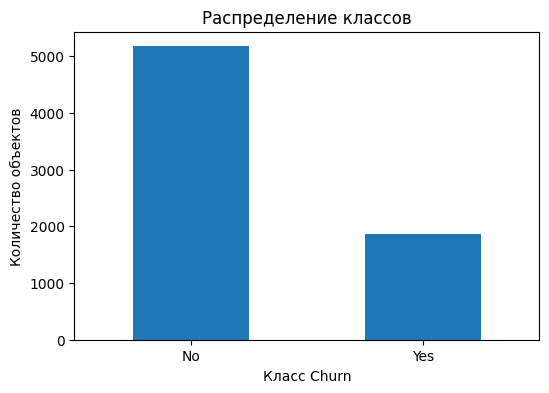

In [20]:
df["Churn"].value_counts().plot(kind="bar", figsize=(6, 4))
plt.title("Распределение классов")
plt.xlabel("Класс Churn")
plt.ylabel("Количество объектов")
plt.xticks(rotation=0)
plt.show()

## 7 Распределения числовых признаков

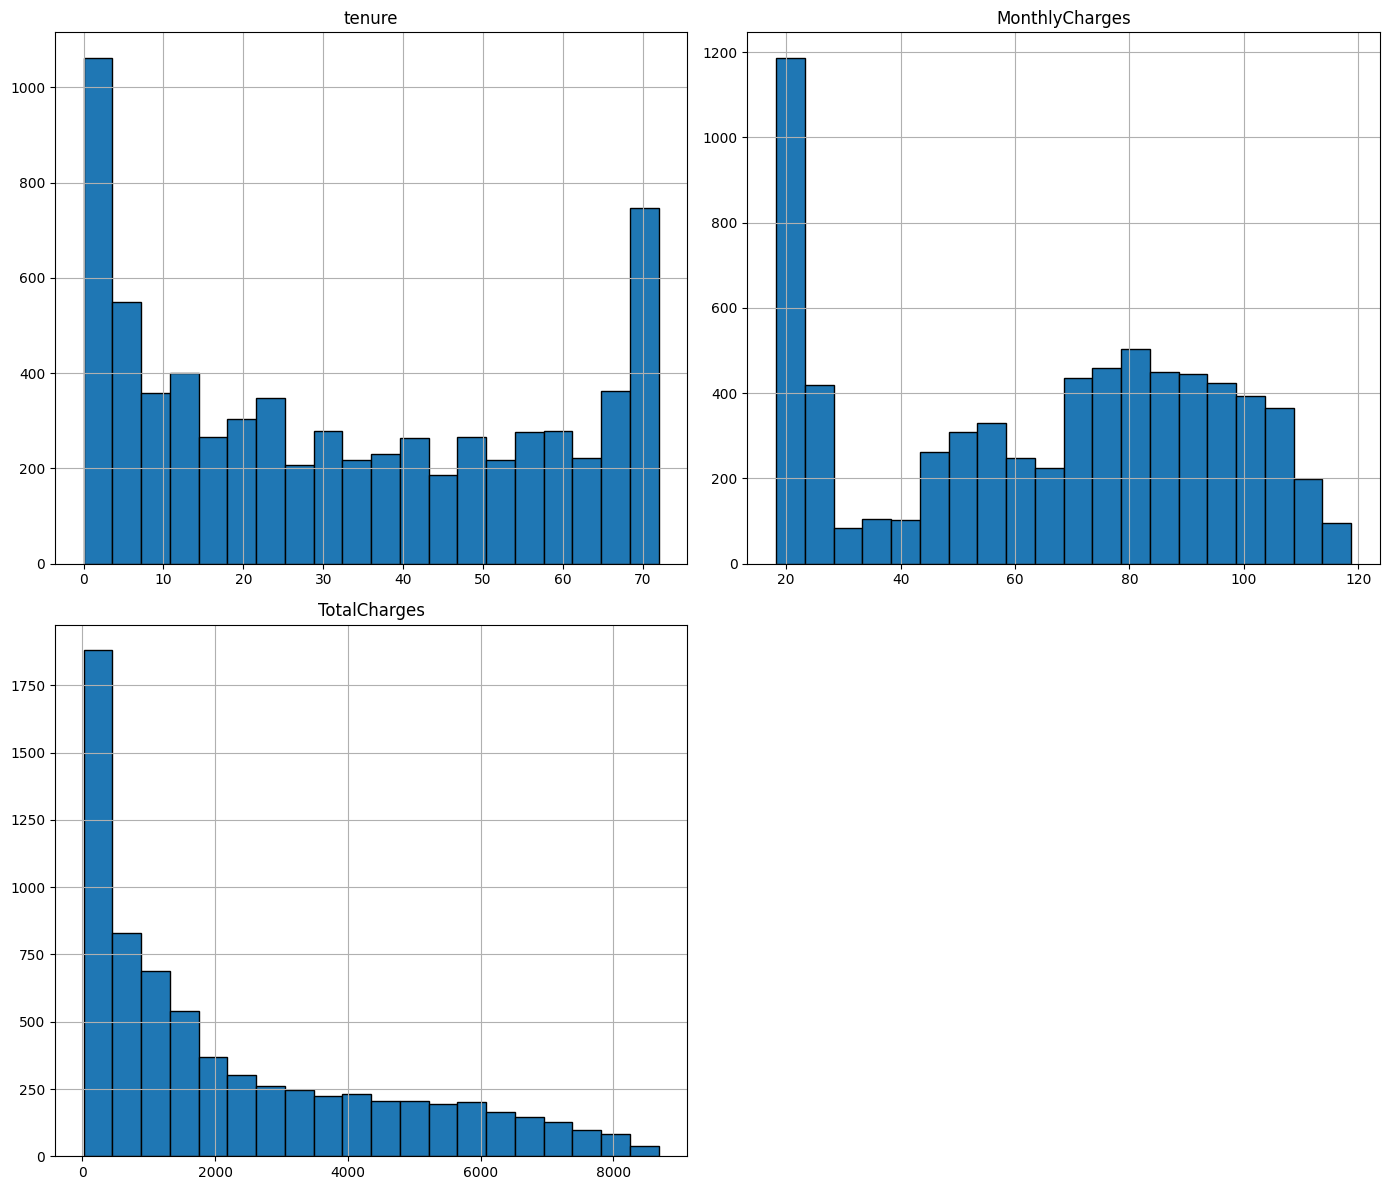

In [21]:
numeric_df = df.select_dtypes(include="number")
features = numeric_df.drop(columns="SeniorCitizen", errors="ignore")
features.hist(bins=20, figsize=(14, 12), edgecolor="black")
plt.tight_layout()
plt.show()

## 8 Boxplot одного признака
Для другого признака достаточно изменить значение `column`.

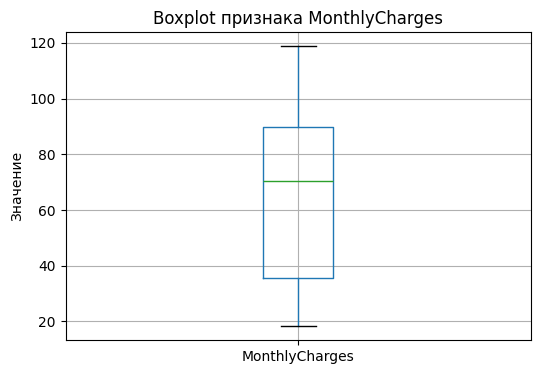

In [22]:
column = "MonthlyCharges"
df.boxplot(column=column, figsize=(6, 4))
plt.title(f"Boxplot признака {column}")
plt.ylabel("Значение")
plt.show()

Линия внутри ящика — медиана, ящик охватывает центральные 50% значений. Отдельные точки за усами — потенциальные выбросы

## 10 Краткий итог аудита

In [23]:
print("Количество строк:", len(df))
print("Количество столбцов:", len(df.columns))
print("Пропущенных ячеек:", df.isna().sum().sum())
print("Полных копий:", df.duplicated().sum())

Количество строк: 7043
Количество столбцов: 21
Пропущенных ячеек: 11
Полных копий: 0


## 11 Предобработка данных

In [24]:
# df["TotalCharges"] = df["TotalCharges"].fillna(df["TotalCharges"].median()) # если есть пропуски заполняем

In [25]:
# df[df.duplicated()] # посмотреть сами дубли
# df = df.drop_duplicates() # удаление дубликатов